# Lab 1 – Partie 2 : Classification multi-classe avec PyTorch
**Master MBD – Deep Learning** | Dataset : *Machine Predictive Maintenance Classification* (Kaggle, `shivamb`)

**Objectif** : prédire le type de panne (`Failure Type`) d'une machine à partir de mesures de capteurs, avec un MLP/DNN PyTorch.

**Plan du notebook**
1. Prétraitement (nettoyage, encodage, split, standardisation)
2. Analyse exploratoire (EDA)
3. Data augmentation pour équilibrer les classes (SMOTE-NC)
4. Architecture DNN PyTorch
5. Recherche d'hyper-paramètres avec `GridSearchCV` (sklearn)
6. Courbes Loss/Epochs et Accuracy/Epochs (train & test)
7. Métriques (accuracy, sensibilité, F1…) sur train et test
8. Techniques de régularisation et comparaison avec le premier modèle
9. Synthèse

> Outils : Google Colab ou Kaggle (GPU conseillé mais pas obligatoire, les données sont tabulaires).

In [4]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)

Device : cpu


## 1. Prétraitement des données
### 1.1 Chargement
Le code cherche le CSV sur Kaggle, en local ou dans Colab ; sinon il le télécharge avec `kagglehub`.

In [6]:
df = pd.read_csv("predictive_maintenance.csv")
print("Fichier : predictive_maintenance.csv", "| Shape :", df.shape)
df.head()

Fichier : predictive_maintenance.csv | Shape : (10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


### 1.2 Nettoyage
- Renommage des colonnes (suppression des crochets/espaces).
- Vérification des valeurs manquantes et des doublons.
- Suppression des colonnes identifiants (`UDI`, `Product ID`) : elles n'ont aucun pouvoir prédictif.
- `Target` (0/1) est une version binaire de `Failure Type` : on la retire pour éviter une **fuite d'information** (data leakage).

In [7]:
df = df.rename(columns={
    "Air temperature [K]": "air_temp", "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rot_speed", "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear", "Failure Type": "failure_type"})

print("Valeurs manquantes :\n", df.isna().sum(), "\n")
print("Doublons :", df.duplicated().sum())
print("\nTypes :\n", df.dtypes)

Valeurs manquantes :
 UDI             0
Product ID      0
Type            0
air_temp        0
process_temp    0
rot_speed       0
torque          0
tool_wear       0
Target          0
failure_type    0
dtype: int64 

Doublons : 0

Types :
 UDI               int64
Product ID       object
Type             object
air_temp        float64
process_temp    float64
rot_speed         int64
torque          float64
tool_wear         int64
Target            int64
failure_type     object
dtype: object


**Incohérences d'étiquetage connues dans ce dataset** : certaines lignes ont `Target=1` alors que `failure_type = "No Failure"`, et la classe `Random Failures` apparaît avec `Target=0` (une panne sans panne). Ces lignes sont contradictoires, on les supprime.

In [8]:
inconsistent = (((df["Target"] == 0) & (df["failure_type"] != "No Failure")) |
                ((df["Target"] == 1) & (df["failure_type"] == "No Failure")))
print("Lignes incohérentes supprimées :", inconsistent.sum())
print(df.loc[inconsistent, "failure_type"].value_counts())

df_clean = df.loc[~inconsistent].drop(columns=["UDI", "Product ID", "Target"]).reset_index(drop=True)
print("\nShape après nettoyage :", df_clean.shape)
df_clean["failure_type"].value_counts()

Lignes incohérentes supprimées : 27
failure_type
Random Failures    18
No Failure          9
Name: count, dtype: int64

Shape après nettoyage : (9973, 7)


failure_type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64

### 1.3 Encodage
- `Type` (L < M < H, qualité du produit) : encodage ordinal.
- `failure_type` (cible) : `LabelEncoder`.

In [9]:
df_clean["Type"] = df_clean["Type"].map({"L": 0, "M": 1, "H": 2})

le = LabelEncoder()
df_clean["label"] = le.fit_transform(df_clean["failure_type"])
CLASS_NAMES = list(le.classes_)
N_CLASSES = len(CLASS_NAMES)
print(dict(zip(range(N_CLASSES), CLASS_NAMES)))

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Tool Wear Failure'}


## 2. Analyse exploratoire (EDA)

,count,mean,std,min,25%,50%,75%,max
air_temp,9973.0,300.003259,2.000548,295.3,298.3,300.1,301.5,304.5
process_temp,9973.0,310.004031,1.483692,305.7,308.8,310.1,311.1,313.8
rot_speed,9973.0,1538.893212,179.412171,1168.0,1423.0,1503.0,1612.0,2886.0
torque,9973.0,39.978993,9.966805,3.8,33.2,40.1,46.7,76.6
tool_wear,9973.0,107.921087,63.649152,0.0,53.0,108.0,162.0,253.0


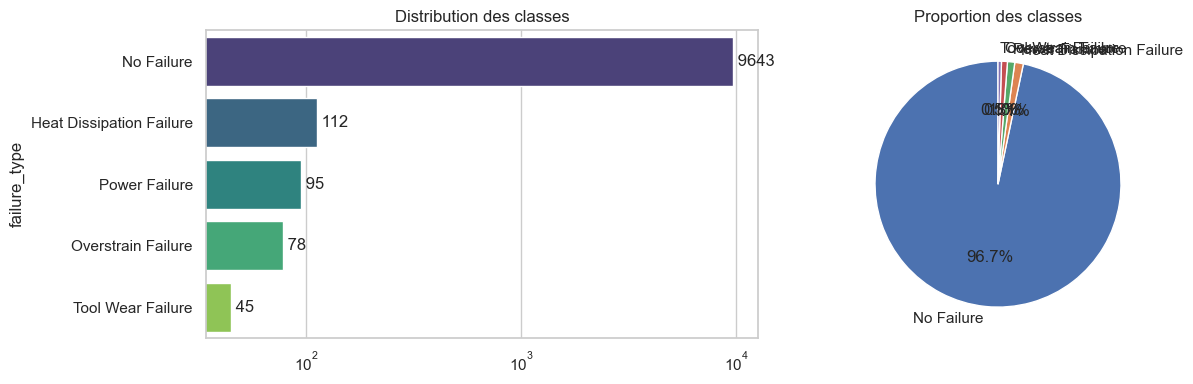

In [10]:
FEATURES = ["Type", "air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]
NUM_FEATURES = FEATURES[1:]
display(df_clean[NUM_FEATURES].describe().T)

# Distribution des classes (très déséquilibrée)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts = df_clean["failure_type"].value_counts()
sns.barplot(x=counts.values, y=counts.index, ax=ax[0], palette="viridis")
ax[0].set_title("Distribution des classes"); ax[0].set_xscale("log")
for i, v in enumerate(counts.values): ax[0].text(v, i, f" {v}", va="center")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Proportion des classes")
plt.tight_layout(); plt.show()

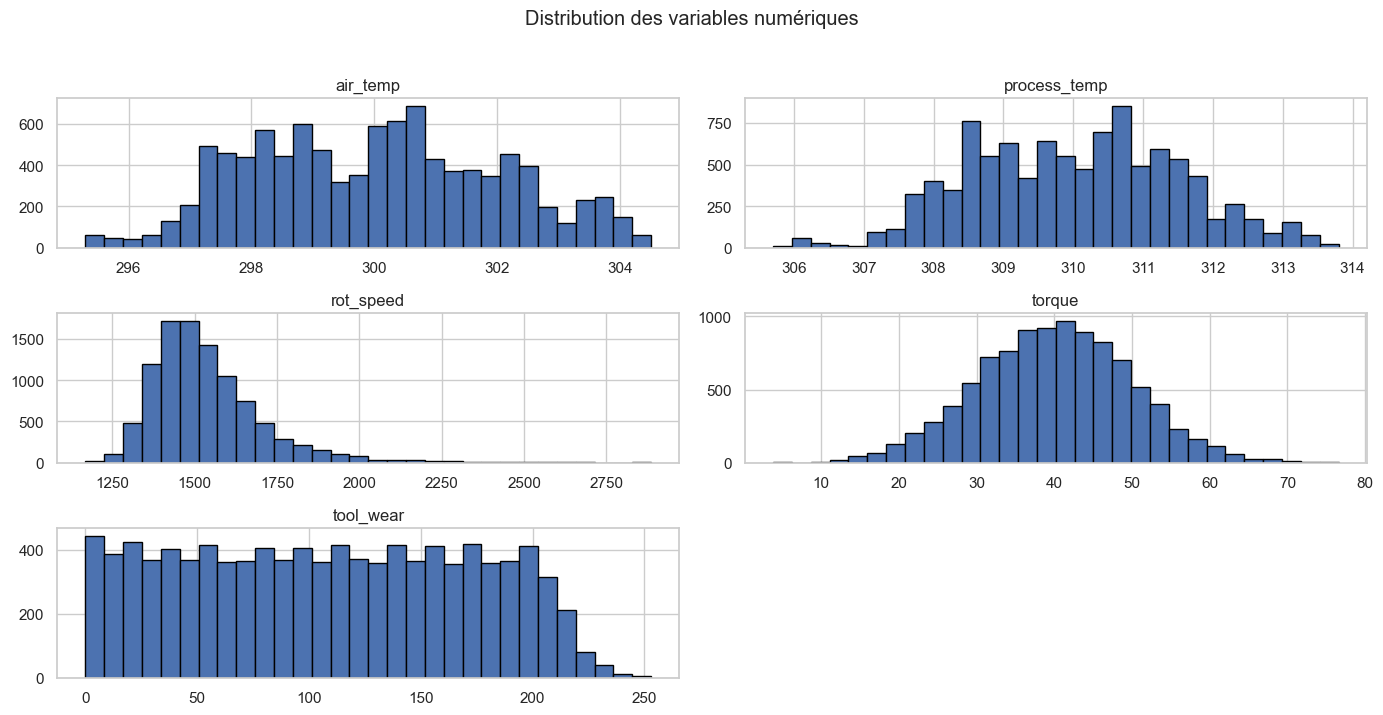

In [11]:
# Histogrammes des variables numériques
df_clean[NUM_FEATURES].hist(bins=30, figsize=(14, 7), edgecolor="black")
plt.suptitle("Distribution des variables numériques", y=1.02); plt.tight_layout(); plt.show()

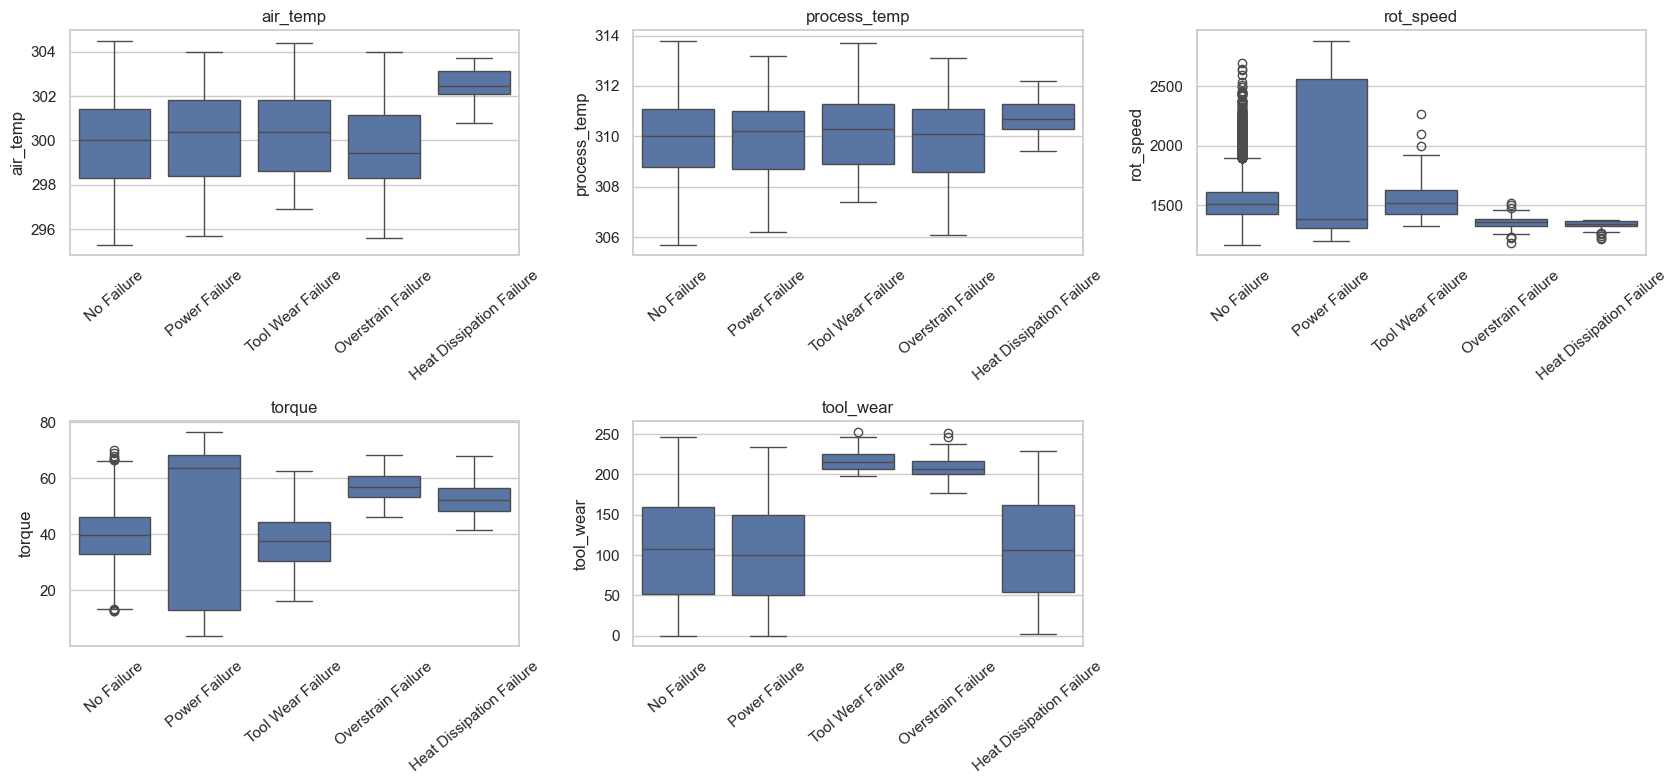

In [12]:
# Boxplots par type de panne
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    sns.boxplot(data=df_clean, x="failure_type", y=col, ax=ax)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40); ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

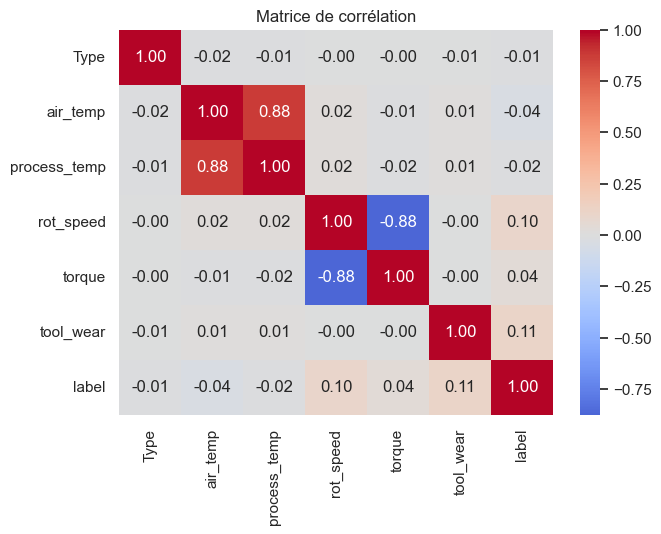

failure_type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Tool Wear Failure
Type,,,,,
H,0.008,0.980,0.001,0.005,0.006
L,0.012,0.961,0.012,0.010,0.004
M,0.010,0.974,0.001,0.010,0.005


In [13]:
# Corrélations
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[FEATURES + ["label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation"); plt.show()

# Type de produit vs panne
pd.crosstab(df_clean["Type"].map({0: "L", 1: "M", 2: "H"}), df_clean["failure_type"], normalize="index").round(3)

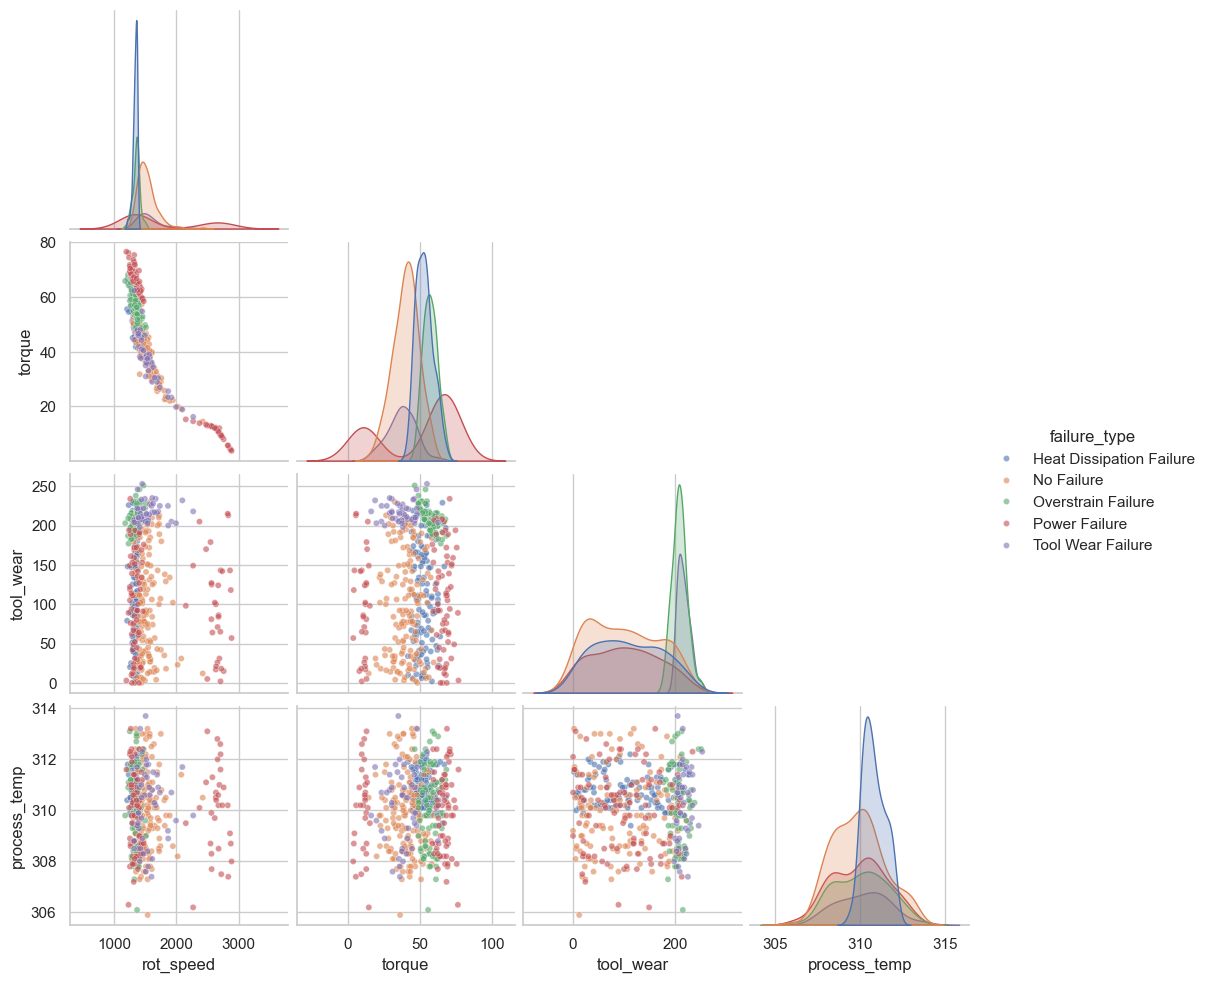

In [15]:
# Relations entre variables, colorées par type de panne (sous-échantillon pour la lisibilité)
sample = df_clean.groupby("failure_type", group_keys=False).apply(lambda g: g.sample(min(len(g), 150), random_state=SEED))
sns.pairplot(sample, vars=["rot_speed", "torque", "tool_wear", "process_temp"], hue="failure_type",
             corner=True, plot_kws={"alpha": 0.6, "s": 20})
plt.show()

**Observations attendues** : (i) la classe `No Failure` représente ~97 % des données → fort déséquilibre ; (ii) `rot_speed` et `torque` sont fortement (anti-)corrélés ; (iii) les pannes se distinguent par des régimes particuliers (couple élevé + vitesse faible pour *Power/Overstrain*, usure élevée pour *Tool Wear*, faible écart de température + faible vitesse pour *Heat Dissipation*).

## 3. Split, data augmentation et standardisation
pour éviter toute fuite de données :
1. On **sépare d'abord** train/test (stratifié) → le test reste intact et réel.
2. On applique **SMOTE-NC** (génération de points synthétiques pour les classes minoritaires) **uniquement sur le train**. `SMOTENC` gère la variable catégorielle `Type`.
3. On **standardise** (moyenne 0, écart-type 1) avec des statistiques calculées sur le train.

Train : (7978, 6) | Test : (1995, 6)


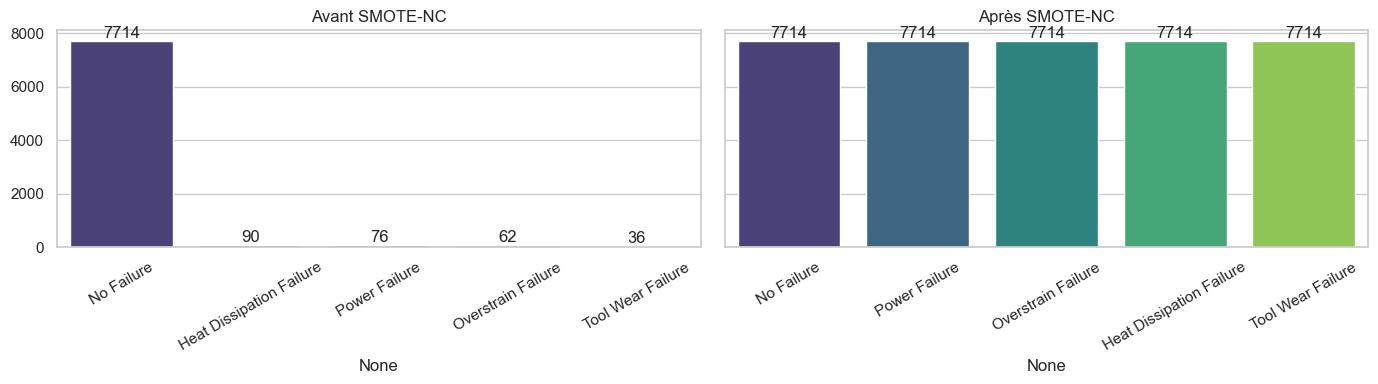

In [16]:
X = df_clean[FEATURES].values.astype(np.float32)
y = df_clean["label"].values

X_train_raw, X_test_raw, y_train_raw, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train :", X_train_raw.shape, "| Test :", X_test_raw.shape)

smote = SMOTENC(categorical_features=[0], random_state=SEED)   # colonne 0 = Type
X_train_res, y_train_res = smote.fit_resample(X_train_raw, y_train_raw)

scaler = StandardScaler().fit(X_train_res)
X_train_s     = scaler.transform(X_train_res).astype(np.float32)   # train augmenté (apprentissage)
X_train_orig_s = scaler.transform(X_train_raw).astype(np.float32)  # train original (évaluation)
X_test_s      = scaler.transform(X_test_raw).astype(np.float32)

# Avant / après augmentation
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, yy, t in zip(ax, [y_train_raw, y_train_res], ["Avant SMOTE-NC", "Après SMOTE-NC"]):
    c = pd.Series(yy).map(dict(enumerate(CLASS_NAMES))).value_counts()
    sns.barplot(x=c.index, y=c.values, ax=a, palette="viridis"); a.set_title(t)
    a.tick_params(axis="x", rotation=30)
    for i, v in enumerate(c.values): a.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 4. Architecture DNN (PyTorch)
Un MLP configurable : `Linear → (BatchNorm) → ReLU → (Dropout)` répété pour chaque couche cachée, puis une couche de sortie à `N_CLASSES` logits (la `Softmax` est incluse dans `CrossEntropyLoss`).

Pour pouvoir utiliser `GridSearchCV` de sklearn, on enveloppe le réseau dans un **estimateur compatible sklearn** (`fit`, `predict`, `get_params`). Il enregistre aussi l'historique loss/accuracy par epoch.

In [17]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, n_classes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def make_optimizer(name, params, lr, weight_decay):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(name)


class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=30, batch_size=512,
                 dropout=0.0, weight_decay=0.0, batchnorm=False, patience=0, random_state=SEED):
        self.hidden = hidden; self.lr = lr; self.optimizer = optimizer; self.epochs = epochs
        self.batch_size = batch_size; self.dropout = dropout; self.weight_decay = weight_decay
        self.batchnorm = batchnorm; self.patience = patience; self.random_state = random_state

    def _eval(self, X, y, loss_fn):
        self.model_.eval()
        with torch.no_grad():
            out = self.model_(torch.as_tensor(X).to(DEVICE))
            yt = torch.as_tensor(y, dtype=torch.long).to(DEVICE)
            return loss_fn(out, yt).item(), (out.argmax(1) == yt).float().mean().item()

    def fit(self, X, y, X_val=None, y_val=None):
        torch.manual_seed(self.random_state); np.random.seed(self.random_state)
        X = np.asarray(X, dtype=np.float32); y = np.asarray(y)
        self.classes_ = np.unique(y)
        yi = np.searchsorted(self.classes_, y)

        # Early stopping : on réserve 10 % du train (jamais le test !)
        X_es = None
        if self.patience > 0:
            perm = np.random.RandomState(self.random_state).permutation(len(X))
            nv = int(0.1 * len(X))
            X_es, y_es, X, yi = X[perm[:nv]], yi[perm[:nv]], X[perm[nv:]], yi[perm[nv:]]

        self.model_ = MLP(X.shape[1], self.hidden, len(self.classes_), self.dropout, self.batchnorm).to(DEVICE)
        opt = make_optimizer(self.optimizer, self.model_.parameters(), self.lr, self.weight_decay)
        loss_fn = nn.CrossEntropyLoss()
        loader = DataLoader(TensorDataset(torch.as_tensor(X), torch.as_tensor(yi, dtype=torch.long)),
                            batch_size=self.batch_size, shuffle=True)
        if X_val is not None:
            X_val = np.asarray(X_val, dtype=np.float32); yv = np.searchsorted(self.classes_, y_val)

        self.history_ = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
        best, wait, best_state = float("inf"), 0, None
        for ep in range(self.epochs):
            self.model_.train(); tot = correct = n = 0
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt.zero_grad(); out = self.model_(xb); loss = loss_fn(out, yb)
                loss.backward(); opt.step()
                tot += loss.item() * len(xb); correct += (out.argmax(1) == yb).sum().item(); n += len(xb)
            self.history_["train_loss"].append(tot / n); self.history_["train_acc"].append(correct / n)
            if X_val is not None:
                l, a = self._eval(X_val, yv, loss_fn)
                self.history_["test_loss"].append(l); self.history_["test_acc"].append(a)
            if X_es is not None:
                l, _ = self._eval(X_es, y_es, loss_fn)
                if l < best - 1e-4:
                    best, wait = l, 0
                    best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
                else:
                    wait += 1
                    if wait >= self.patience: break
        if best_state is not None: self.model_.load_state_dict(best_state)
        return self

    def predict_proba(self, X):
        self.model_.eval()
        with torch.no_grad():
            out = self.model_(torch.as_tensor(np.asarray(X, dtype=np.float32)).to(DEVICE))
            return torch.softmax(out, 1).cpu().numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


# Test rapide
m = TorchMLPClassifier(epochs=3).fit(X_train_s, y_train_res)
print("OK – acc train (3 epochs) :", accuracy_score(y_train_res, m.predict(X_train_s)))
print(m.model_)

OK – acc train (3 epochs) : 0.940238527352865
MLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=5, bias=True)
  )
)


## 5. Recherche d'hyper-paramètres avec `GridSearchCV`
Pour éviter que des points synthétiques (SMOTE) se retrouvent dans les folds de validation (ce qui gonflerait artificiellement le score), on place **SMOTE-NC → StandardScaler → réseau dans un seul `Pipeline`** : à chaque fold, l'augmentation est faite uniquement sur la partie apprentissage. Le score utilisé est le **F1 macro**, plus pertinent que l'accuracy sur des classes déséquilibrées.

Hyper-paramètres explorés : learning rate, optimiseur, nombre d'epochs, architecture (profondeur/largeur).


In [18]:
pipe = ImbPipeline([
    ("smote",  SMOTENC(categorical_features=[0], random_state=SEED)),
    ("scaler", StandardScaler()),
    ("clf",    TorchMLPClassifier()),
])

param_grid = {
    "clf__lr":        [1e-3, 1e-2],
    "clf__optimizer": ["adam", "rmsprop", "sgd"],
    "clf__epochs":    [20, 40],
    "clf__hidden":    [(64, 32), (128, 64, 32)],
}

gs = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                  cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                  n_jobs=1, verbose=2, refit=False)
gs.fit(X_train_raw, y_train_raw)

print("\nMeilleur F1 macro (CV) :", round(gs.best_score_, 4))
print("Meilleurs hyper-paramètres :", gs.best_params_)

res = pd.DataFrame(gs.cv_results_)
res[["param_clf__lr", "param_clf__optimizer", "param_clf__epochs", "param_clf__hidden",
     "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=   9.4s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=  13.2s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=  10.2s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=rmsprop; total time=  10.2s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=rmsprop; total time=   8.6s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=rmsprop; total time=   8.3s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   8.0s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   8.3s
[CV] END clf__epochs=20, clf__hidden=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   9.5s
[CV] END clf__e

,param_clf__lr,param_clf__optimizer,param_clf__epochs,param_clf__hidden,mean_test_score,std_test_score,rank_test_score
15,0.010,adam,40,"(64, 32)",0.674694,0.016327,1
9,0.010,adam,20,"(128, 64, 32)",0.653839,0.022691,2
22,0.010,rmsprop,40,"(128, 64, 32)",0.650814,0.008063,3
3,0.010,adam,20,"(64, 32)",0.650029,0.013610,4
21,0.010,adam,40,"(128, 64, 32)",0.644598,0.029805,5
16,0.010,rmsprop,40,"(64, 32)",0.641713,0.014556,6
18,0.001,adam,40,"(128, 64, 32)",0.633092,0.010930,7
4,0.010,rmsprop,20,"(64, 32)",0.631936,0.006240,8
10,0.010,rmsprop,20,"(128, 64, 32)",0.630584,0.022715,9
19,0.001,rmsprop,40,"(128, 64, 32)",0.619381,0.006651,10


In [19]:
best_params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
print(best_params)

{'epochs': 40, 'hidden': (64, 32), 'lr': 0.01, 'optimizer': 'adam'}


## 6. Entraînement du modèle final et courbes Loss / Accuracy
On ré-entraîne le meilleur modèle sur le train augmenté, en suivant la loss et l'accuracy du **train** et du **test** à chaque epoch.

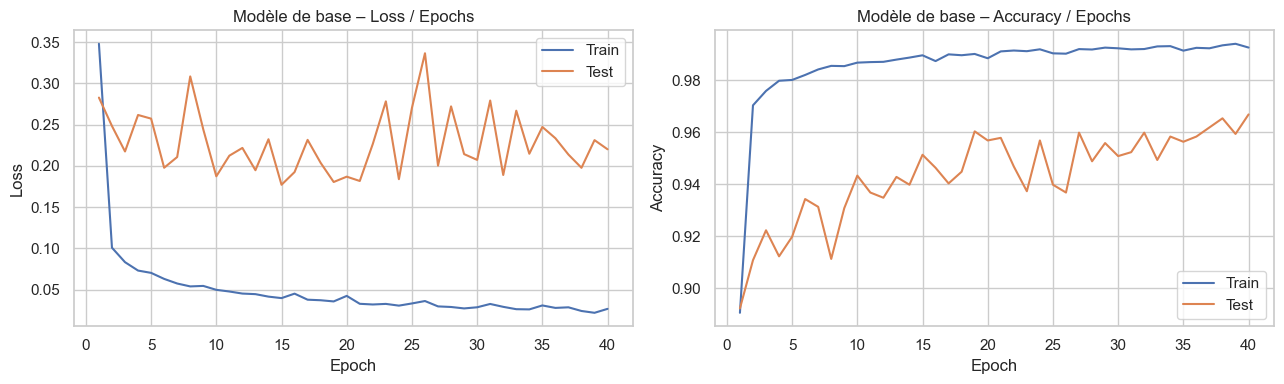

In [20]:
def plot_history(h, title="Modèle"):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, h["train_loss"], label="Train"); ax[0].plot(ep, h["test_loss"], label="Test")
    ax[0].set(title=f"{title} – Loss / Epochs", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="Train"); ax[1].plot(ep, h["test_acc"], label="Test")
    ax[1].set(title=f"{title} – Accuracy / Epochs", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

base_model = TorchMLPClassifier(**best_params).fit(X_train_s, y_train_res, X_val=X_test_s, y_val=y_test)
plot_history(base_model.history_, "Modèle de base")

## 7. Métriques sur train et test
Accuracy, précision, **sensibilité (recall)**, F1 (macro et pondéré). Le train est évalué sur les données **originales** (non augmentées), pour une comparaison honnête avec le test.

,Train,Test
accuracy,0.9782,0.9669
precision (macro),0.7691,0.6676
sensibilité (macro),0.9780,0.8299
F1 (macro),0.8209,0.7203
F1 (pondéré),0.9839,0.9749


Rapport de classification – TEST

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.81      0.95      0.88        22
              No Failure       1.00      0.97      0.98      1929
      Overstrain Failure       0.75      0.94      0.83        16
           Power Failure       0.70      0.84      0.76        19
       Tool Wear Failure       0.09      0.44      0.15         9

                accuracy                           0.97      1995
               macro avg       0.67      0.83      0.72      1995
            weighted avg       0.98      0.97      0.97      1995



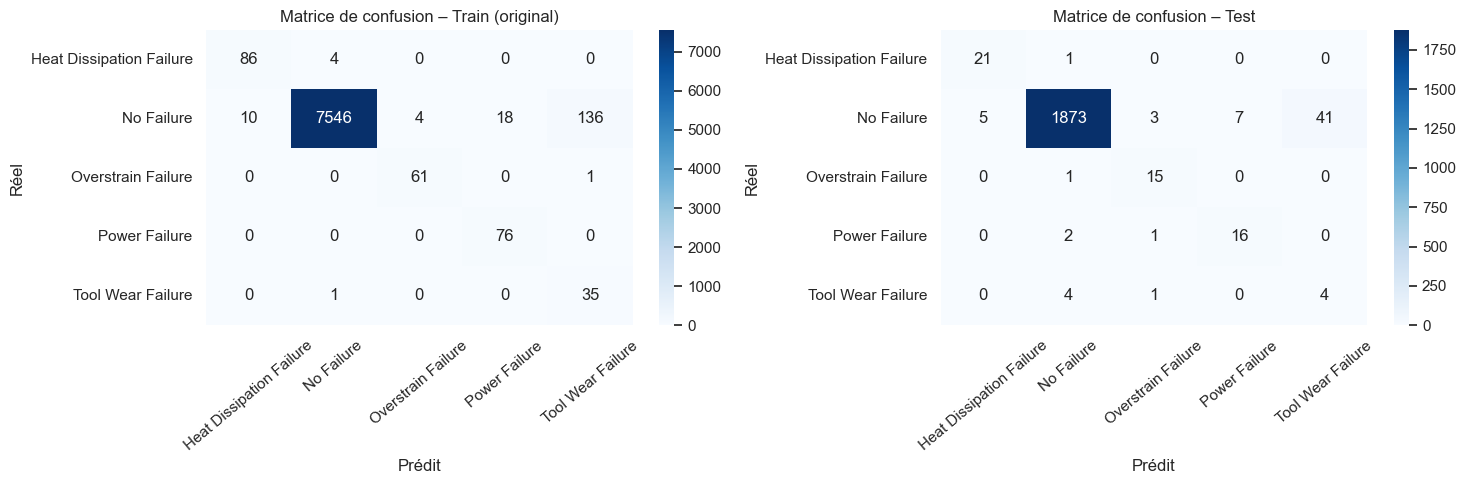

In [21]:
def compute_metrics(model, X, y):
    p = model.predict(X)
    return {"accuracy":          accuracy_score(y, p),
            "precision (macro)": precision_score(y, p, average="macro", zero_division=0),
            "sensibilité (macro)": recall_score(y, p, average="macro", zero_division=0),
            "F1 (macro)":        f1_score(y, p, average="macro", zero_division=0),
            "F1 (pondéré)":      f1_score(y, p, average="weighted", zero_division=0)}

metrics_base = pd.DataFrame({"Train": compute_metrics(base_model, X_train_orig_s, y_train_raw),
                             "Test":  compute_metrics(base_model, X_test_s, y_test)}).round(4)
display(metrics_base)

y_pred_test = base_model.predict(X_test_s)
print("Rapport de classification – TEST\n")
print(classification_report(y_test, y_pred_test, target_names=CLASS_NAMES, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, (Xe, ye, t) in zip(ax, [(X_train_orig_s, y_train_raw, "Train (original)"), (X_test_s, y_test, "Test")]):
    cm = confusion_matrix(ye, base_model.predict(Xe))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a)
    a.set(title=f"Matrice de confusion – {t}", xlabel="Prédit", ylabel="Réel")
    a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

## 8. Techniques de régularisation
On compare au modèle de base (mêmes hyper-paramètres issus du GridSearch) :
| Technique | Principe |
|---|---|
| **Dropout** | désactive aléatoirement des neurones pendant l'entraînement |
| **L2 (weight decay)** | pénalise les poids de grande amplitude |
| **Batch Normalization** | stabilise et régularise les activations |
| **Early stopping** | arrête l'entraînement quand la loss de validation (10 % du train) ne s'améliore plus |
| **Combinaison** | toutes les techniques ensemble |

In [22]:
configs = {
    "Base":                {},
    "Dropout (0.3)":       {"dropout": 0.3},
    "L2 (wd=1e-3)":        {"weight_decay": 1e-3},
    "BatchNorm":           {"batchnorm": True},
    "Early stopping (p=5)": {"patience": 5, "epochs": max(best_params["epochs"], 60)},
    "Combinaison":         {"dropout": 0.2, "weight_decay": 1e-4, "batchnorm": True,
                            "patience": 5, "epochs": max(best_params["epochs"], 60)},
}

models, rows = {}, []
for name, extra in configs.items():
    if name == "Base":
        mdl = base_model
    else:
        mdl = TorchMLPClassifier(**{**best_params, **extra}).fit(X_train_s, y_train_res,
                                                                  X_val=X_test_s, y_val=y_test)
    models[name] = mdl
    tr = compute_metrics(mdl, X_train_orig_s, y_train_raw); te = compute_metrics(mdl, X_test_s, y_test)
    rows.append({"Modèle": name,
                 "Acc train": tr["accuracy"], "Acc test": te["accuracy"],
                 "Sensib. test (macro)": te["sensibilité (macro)"],
                 "F1 train (macro)": tr["F1 (macro)"], "F1 test (macro)": te["F1 (macro)"],
                 "Écart F1 train-test": tr["F1 (macro)"] - te["F1 (macro)"]})

comparison = pd.DataFrame(rows).set_index("Modèle").round(4)
comparison

,Acc train,Acc test,Sensib. test (macro),F1 train (macro),F1 test (macro),Écart F1 train-test
Modèle,,,,,,
Base,0.9782,0.9669,0.8299,0.8209,0.7203,0.1006
Dropout (0.3),0.9413,0.9283,0.9305,0.6946,0.6473,0.0473
L2 (wd=1e-3),0.9401,0.9303,0.9011,0.6717,0.6465,0.0252
BatchNorm,0.9705,0.9529,0.8216,0.7990,0.6782,0.1208
Early stopping (p=5),0.9638,0.9519,0.8523,0.7570,0.6861,0.0708
Combinaison,0.9354,0.9198,0.8872,0.6653,0.6241,0.0412


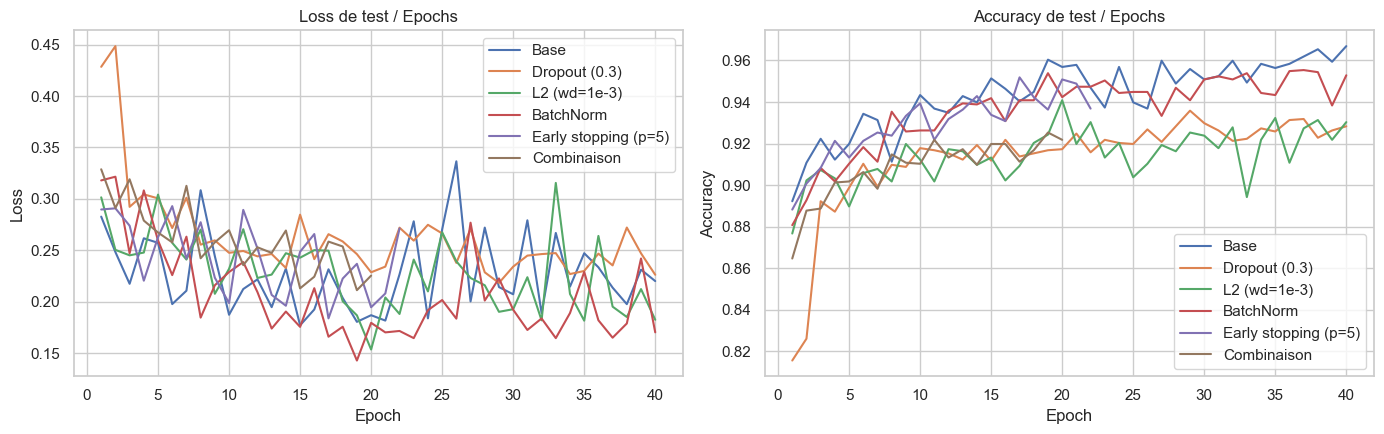

Base                     loss train = 0.0267 | loss test = 0.2201
Dropout (0.3)            loss train = 0.0703 | loss test = 0.2263
L2 (wd=1e-3)             loss train = 0.0664 | loss test = 0.1825
BatchNorm                loss train = 0.0320 | loss test = 0.1703
Early stopping (p=5)     loss train = 0.0382 | loss test = 0.2713
Combinaison              loss train = 0.0757 | loss test = 0.2254


In [23]:
# Courbes comparées : loss de test et accuracy de test
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, mdl in models.items():
    h = mdl.history_
    ax[0].plot(range(1, len(h["test_loss"]) + 1), h["test_loss"], label=name)
    ax[1].plot(range(1, len(h["test_acc"]) + 1), h["test_acc"], label=name)
ax[0].set(title="Loss de test / Epochs", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].set(title="Accuracy de test / Epochs", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

# Écart train/test (loss) pour chaque modèle = indicateur de sur-apprentissage
for name, mdl in models.items():
    h = mdl.history_
    print(f"{name:24s} loss train = {h['train_loss'][-1]:.4f} | loss test = {h['test_loss'][-1]:.4f}")

Meilleur modèle : Base 

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.81      0.95      0.88        22
              No Failure       1.00      0.97      0.98      1929
      Overstrain Failure       0.75      0.94      0.83        16
           Power Failure       0.70      0.84      0.76        19
       Tool Wear Failure       0.09      0.44      0.15         9

                accuracy                           0.97      1995
               macro avg       0.67      0.83      0.72      1995
            weighted avg       0.98      0.97      0.97      1995



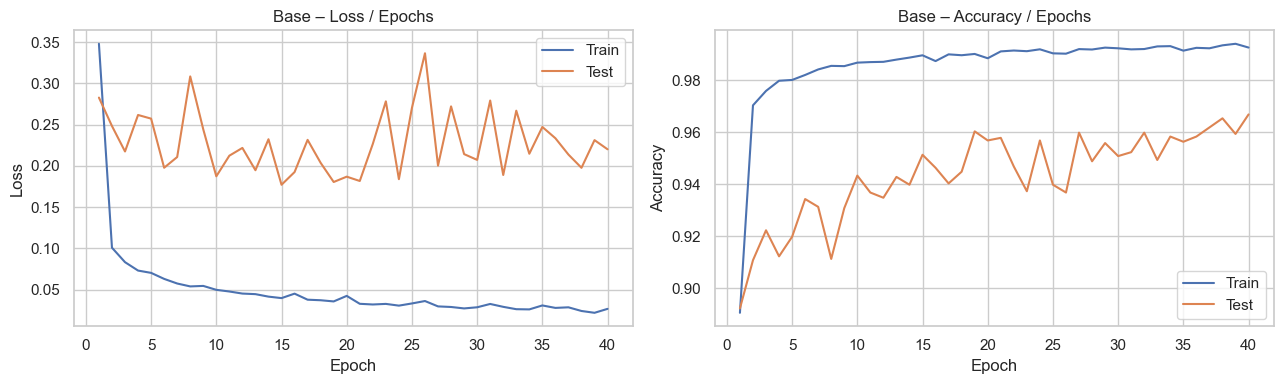

In [24]:
# Meilleur modèle régularisé (selon F1 macro test) : rapport détaillé
best_name = comparison["F1 test (macro)"].idxmax()
print("Meilleur modèle :", best_name, "\n")
print(classification_report(y_test, models[best_name].predict(X_test_s), target_names=CLASS_NAMES, zero_division=0))
plot_history(models[best_name].history_, best_name)

## 9. Synthèse de ce que j'ai appris
- **PyTorch** : construction d'un MLP (`nn.Module`), boucle d'entraînement (forward / loss / backward / step), `DataLoader`, suivi des courbes loss/accuracy.
- **Prétraitement** : nettoyage des incohérences, suppression des identifiants et de la fuite de données (`Target`), encodage, standardisation calculée sur le train uniquement.
- **Déséquilibre des classes** : l'accuracy est trompeuse (~97 % en prédisant toujours « No Failure ») ; on utilise F1 macro et sensibilité par classe. SMOTE-NC rééquilibre le train, mais doit être appliqué **après le split** et **à l'intérieur des folds** de la validation croisée.
- **GridSearchCV** : en enveloppant le réseau dans un estimateur sklearn et un `Pipeline`, on peut régler learning rate, optimiseur, epochs et architecture proprement.
- **Régularisation** : dropout, L2, batch norm et early stopping réduisent l'écart train/test ; leur effet réel doit être mesuré, pas supposé.
- **Limites** : peu d'exemples réels des classes rares → les données synthétiques n'apportent pas d'information nouvelle et les métriques de test restent bruitées.